<a href="https://colab.research.google.com/github/2025cssumeetsinghthakurg/4IK25CS214_DAV_LAB/blob/main/LAB11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt


In [ ]:

df = pd.read_csv('/content/House_Price_dataset.csv')
df = df[df['purpose'] == 'For Sale']
df = df[['price', 'bedrooms', 'baths', 'Area Size']].dropna()


df = df[(df['bedrooms'] > 0) & (df['baths'] > 0)]
df = df[df['price'] < df['price'].quantile(0.99)]
df = df[df['Area Size'] < df['Area Size'].quantile(0.99)]

In [ ]:
df=df.sample(n=100,random_state=42).reset_index(drop=True)


In [ ]:
X=df[['price','bedrooms','baths',"Area Size"]]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

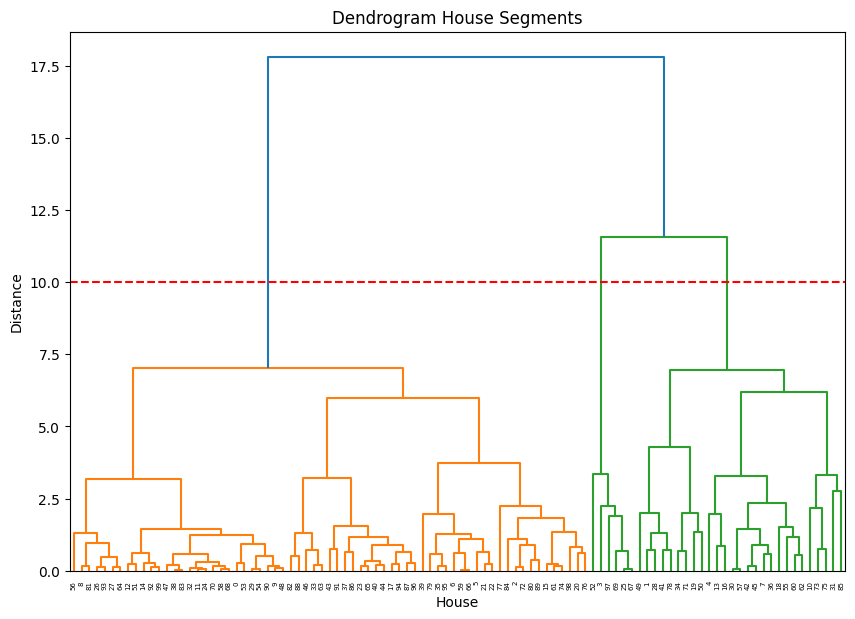

In [ ]:
linked = linkage(X_scaled, 'ward')
plt.figure(figsize=(10, 7))
dendrogram(linked)
plt.title('Dendrogram House Segments')
plt.xlabel('House')
plt.ylabel('Distance')
plt.axhline(y=10, color='red', linestyle='--')
plt.show()

In [ ]:
hc = AgglomerativeClustering(n_clusters=3, linkage='ward')
df["HC_Cluster"] = hc.fit_predict(X_scaled)

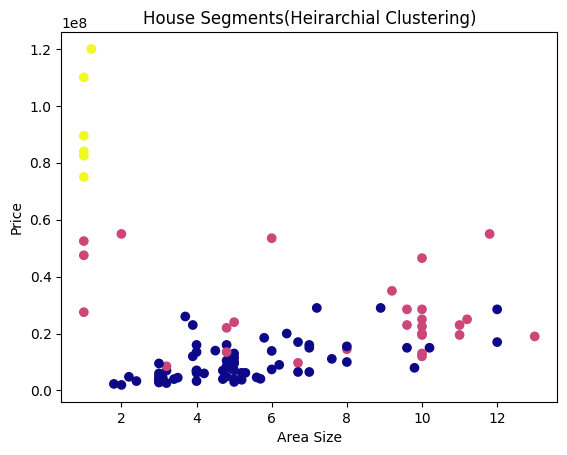

In [ ]:
plt.scatter(df["Area Size"], df["price"], c=df["HC_Cluster"],cmap='plasma')
plt.xlabel("Area Size")
plt.ylabel("Price")
plt.title("House Segments(Heirarchial Clustering)")
plt.show()

In [ ]:
plt.scatter()